# **HR Employee Data Analysis (MNC Dataset)**

## Introduction
This is my first data analysis project in Python using Google Colab. The dataset contains human resources (HR) records for employees across different departments, job titles, experience levels, employment statuses, and salary figures in INR.

The goal of this analysis is to:
- Explore and inspect the structure and quality of the HR dataset
- Clean missing values and format columns properly
- Analyze salary, experience, performance, and department-level trends
- Visualize key patterns using Seaborn charts

In [ ]:
# Import required libraries for data manipulation and visualization

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Load the HR dataset into a DataFrame named 'df'

df=pd.read_csv('/content/HR_Data.csv.crdownload')
df

,Unnamed: 0,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14.0,Resigned,On-site,1585363.0
1,1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7.0,Active,On-site,847686.0
2,2,EMP0000003,Alyssa Martinez,HR,HR Manager,2023-03-20,"Port Christinaport, Saudi Arabia",1,2.0,Active,On-site,1430084.0
3,3,EMP0000004,Nicholas Valdez,IT,Software Engineer,2023-10-12,"Port Shelbychester, Antigua and Barbuda",1,1.0,Active,On-site,990689.0
4,4,EMP0000005,Joel Hendricks,Operations,Logistics Coordinator,2024-12-09,"Lake Kimberly, Palestinian Territory",5,0.0,Active,On-site,535082.0
...,...,...,...,...,...,...,...,...,...,...,...,...
1597,1597,EMP0001598,Eric Collins,IT,Software Engineer,2023-05-13,"Port Yvette, United States Virgin Islands",2,2.0,Active,Remote,744558.0
1598,1598,EMP0001599,Gwendolyn Henderson,Marketing,SEO Specialist,2018-02-08,"Johnsonbury, Brunei Darussalam",4,7.0,Active,Remote,667494.0
1599,1599,EMP0001600,John Gonzales,Operations,Supply Chain Manager,2019-11-01,"Port Justin, Turkey",4,5.0,Active,On-site,983598.0
1600,1600,EMP0001601,Morgan Hester,IT,Data Analyst,2023-03-21,"Port Patriciaton, New Caledonia",2,2.0,Resigned,On-site,951108.0


## 1. Data Inspection & Data Cleaning
Before analyzing patterns or building charts, we inspect the dataset to understand its columns, data types, summary statistics, and data quality issues (such as missing values or duplicates). We also clean unwanted columns, fill missing values, and convert `Hire_Date` into a proper datetime format.

In [ ]:
# Convert Hire_Date from text to datetime format for date-based analysis

df['Hire_Date'] = pd.to_datetime(df['Hire_Date'])

In [ ]:
# Display column names, non-null counts, and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1602 entries, 0 to 1601
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Unnamed: 0          1602 non-null   int64         
 1   Employee_ID         1602 non-null   object        
 2   Full_Name           1602 non-null   object        
 3   Department          1602 non-null   object        
 4   Job_Title           1602 non-null   object        
 5   Hire_Date           1602 non-null   datetime64[ns]
 6   Location            1602 non-null   object        
 7   Performance_Rating  1602 non-null   int64         
 8   Experience_Years    1601 non-null   float64       
 9   Status              1601 non-null   object        
 10  Work_Mode           1601 non-null   object        
 11  Salary_INR          1601 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(7)
memory usage: 150.3+ KB


In [ ]:
# Display summary statistics for numerical columns

df.describe()

,Unnamed: 0,Hire_Date,Performance_Rating,Experience_Years,Salary_INR
count,1602.000000,1602,1602.000000,1601.000000,1.601000e+03
mean,800.500000,2020-01-27 03:06:57.977528064,2.964419,5.032480,8.916926e+05
min,0.000000,2010-08-16 00:00:00,1.000000,0.000000,3.019570e+05
25%,400.250000,2017-05-14 12:00:00,2.000000,2.000000,6.055510e+05
50%,800.500000,2020-07-07 00:00:00,3.000000,5.000000,8.121110e+05
75%,1200.750000,2023-01-16 00:00:00,4.000000,8.000000,1.075621e+06
max,1601.000000,2025-08-12 00:00:00,5.000000,15.000000,2.969027e+06
std,462.601881,NaN,1.422794,3.647286,3.935842e+05


In [ ]:
# Preview the first 3 rows and last 3 rows

df.head(3)

,Unnamed: 0,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14.0,Resigned,On-site,1585363.0
1,1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7.0,Active,On-site,847686.0
2,2,EMP0000003,Alyssa Martinez,HR,HR Manager,2023-03-20,"Port Christinaport, Saudi Arabia",1,2.0,Active,On-site,1430084.0


In [ ]:
df.tail(3)

,Unnamed: 0,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
1599,1599,EMP0001600,John Gonzales,Operations,Supply Chain Manager,2019-11-01,"Port Justin, Turkey",4,5.0,Active,On-site,983598.0
1600,1600,EMP0001601,Morgan Hester,IT,Data Analyst,2023-03-21,"Port Patriciaton, New Caledonia",2,2.0,Resigned,On-site,951108.0
1601,1601,EMP0001602,Mary Gilbert MD,IT,Software Engineer,2020-10-03,"East Kevinfort, Burkina Faso",1,NaN,NaN,NaN,NaN


In [ ]:
# Remove the extra 'Unnamed: 0' column created when saving the CSV

df.drop(['Unnamed: 0'],axis=1,inplace=True)

In [ ]:
# Count missing (null) values in each column before cleaning

df.isnull().sum()

,0
Employee_ID,0
Full_Name,0
Department,0
Job_Title,0
Hire_Date,0
Location,0
Performance_Rating,0
Experience_Years,1
Status,1
Work_Mode,1


In [ ]:
# Calculate average salary for IT Software Engineers to fill missing Salary_INR

IT_SoftwareEngineer_AvgSalary = df[(df['Department'] == 'IT') & (df['Job_Title'] == 'Software Engineer')]['Salary_INR'].mean()

# Fill missing values across key columns
df.fillna({'Work_Mode':'Not Available',
        'Status':'Not Available',
        'Experience_Years':0.0,
        'Salary_INR': IT_SoftwareEngineer_AvgSalary},inplace=True)


In [ ]:
# Check again to confirm missing values are handled

df.isnull().sum()

,0
Employee_ID,0
Full_Name_Of_Employee,0
Department,0
Job_Title,0
Hire_Date,0
Location,0
Performance_Rating,0
Experience_Years,0
Status,0
Work_Mode,0


In [ ]:
# Count duplicate rows in the dataset

df.duplicated().sum()

np.int64(0)

## 2. Dataset Properties, Filtering & Feature Creation
Here we check basic DataFrame attributes, inspect specific rows, filter employees by department and salary threshold, rename the employee name column for clarity, and create a new `Bonus` column calculated as 0.1% of `Salary_INR`.

In [ ]:
# Check dataset dimensions, total elements, column names, number of dimensions, and index

print(df.shape)
print(df.size)

(1602, 11)
17622


In [ ]:
df.columns

Index(['Employee_ID', 'Full_Name', 'Department', 'Job_Title', 'Hire_Date',
       'Location', 'Performance_Rating', 'Experience_Years', 'Status',
       'Work_Mode', 'Salary_INR'],
      dtype='object')

In [ ]:
df.ndim

2

In [ ]:
df.index

RangeIndex(start=0, stop=1602, step=1)

In [ ]:
# Inspect a single row by label (532) and a slice of rows by position (1246 to 1250)

df.loc[532]

,532
Employee_ID,EMP0000533
Full_Name,Audrey Wilcox
Department,IT
Job_Title,Software Engineer
Hire_Date,2016-03-12 00:00:00
Location,"Travisbury, Austria"
Performance_Rating,2
Experience_Years,9.0
Status,Active
Work_Mode,On-site


In [ ]:
df.iloc[1246:1251]

,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
1246,EMP0001247,Jane Sullivan,Marketing,Marketing Executive,2016-02-09,"West Margaret, Heard Island and McDonald Islands",2,9.0,Terminated,On-site,596648.0
1247,EMP0001248,Christine Miller,IT,Software Engineer,2023-01-10,"Gonzalezhaven, Brunei Darussalam",5,2.0,Active,On-site,955629.0
1248,EMP0001249,Jermaine Lee,IT,Software Engineer,2023-01-08,"Gomezfurt, Turkey",3,2.0,Retired,Remote,1714622.0
1249,EMP0001250,Luke Cole,IT,Data Analyst,2022-06-05,"South Morgan, Madagascar",4,3.0,Active,Remote,1086645.0
1250,EMP0001251,Joseph Douglas,Finance,Financial Analyst,2018-01-14,"Donaldsonfort, Djibouti",5,7.0,Active,On-site,762887.0


In [ ]:
# Filter employees in the IT department

df[df['Department']=='IT']

,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14.0,Resigned,On-site,1585363.000
3,EMP0000004,Nicholas Valdez,IT,Software Engineer,2023-10-12,"Port Shelbychester, Antigua and Barbuda",1,1.0,Active,On-site,990689.000
9,EMP0000010,Maria Yu MD,IT,Software Engineer,2015-10-08,"Brownport, Yemen",4,9.0,Active,Remote,1543102.000
18,EMP0000019,Samuel Ferguson,IT,DevOps Engineer,2025-04-05,"Matthewsville, Ghana",2,0.0,Active,On-site,631273.000
21,EMP0000022,Kylie May,IT,DevOps Engineer,2015-07-07,"Houstonland, Qatar",2,10.0,Active,On-site,723820.000
...,...,...,...,...,...,...,...,...,...,...,...
1595,EMP0001596,Kristy Patel,IT,DevOps Engineer,2021-12-14,"Nathanland, Burundi",4,3.0,Active,On-site,680260.000
1596,EMP0001597,Meghan Ramos,IT,Software Engineer,2012-02-26,"East Billberg, Nicaragua",3,13.0,Active,On-site,1477231.000
1597,EMP0001598,Eric Collins,IT,Software Engineer,2023-05-13,"Port Yvette, United States Virgin Islands",2,2.0,Active,Remote,744558.000
1600,EMP0001601,Morgan Hester,IT,Data Analyst,2023-03-21,"Port Patriciaton, New Caledonia",2,2.0,Resigned,On-site,951108.000


In [ ]:
# Filter employees in the HR department

df[df['Department']=='HR']

,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
2,EMP0000003,Alyssa Martinez,HR,HR Manager,2023-03-20,"Port Christinaport, Saudi Arabia",1,2.0,Active,On-site,1430084.0
13,EMP0000014,Roberto Nguyen,HR,HR Executive,2020-08-24,"South Sandraview, India",4,4.0,Active,On-site,572479.0
37,EMP0000038,Doris Lambert,HR,Talent Acquisition Specialist,2019-03-14,"Ayalafurt, Estonia",1,6.0,Active,On-site,892414.0
47,EMP0000048,Tom Mills,HR,HR Executive,2024-01-31,"Johnsonside, Ghana",1,1.0,Active,Remote,565467.0
52,EMP0000053,Keith Diaz,HR,HR Executive,2022-06-08,"New Pamela, Tokelau",1,3.0,Active,On-site,327765.0
...,...,...,...,...,...,...,...,...,...,...,...
1555,EMP0001556,Robert Edwards,HR,Talent Acquisition Specialist,2022-08-05,"Rubenland, Sweden",4,3.0,Active,On-site,473179.0
1575,EMP0001576,Vanessa Ramirez,HR,HR Manager,2018-05-14,"North Melanie, Netherlands",2,7.0,Active,On-site,1139255.0
1576,EMP0001577,Jeffery Turner,HR,Talent Acquisition Specialist,2017-02-04,"New Kevin, Saudi Arabia",5,8.0,Resigned,Remote,1059724.0
1577,EMP0001578,Michelle Lowery,HR,Talent Acquisition Specialist,2021-04-19,"Angelicahaven, Nicaragua",4,4.0,Active,On-site,1162304.0


In [ ]:
# Filter employees earning more than 2,950,000 INR

df[df['Salary_INR']>2950000]

,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
1222,EMP0001223,Elizabeth Porter,IT,IT Manager,2020-11-16,"North Kimberly, Russian Federation",4,4.0,Active,Remote,2969027.0


In [ ]:
# Rename Full_Name to Full_Name_Of_Employee for clearer column naming

df.rename(columns={'Full_Name':'Full_Name_Of_Employee'},inplace=True)
df.head(3)

,Employee_ID,Full_Name_Of_Employee,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14.0,Resigned,On-site,1585363.0
1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7.0,Active,On-site,847686.0
2,EMP0000003,Alyssa Martinez,HR,HR Manager,2023-03-20,"Port Christinaport, Saudi Arabia",1,2.0,Active,On-site,1430084.0


In [ ]:
# Calculate Bonus as 0.1% (0.001) of Salary_INR

df['Bonus']=df['Salary_INR']*0.001
df.head(3)

,Employee_ID,Full_Name_Of_Employee,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR,Bonus
0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14.0,Resigned,On-site,1585363.0,1585.363
1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7.0,Active,On-site,847686.0,847.686
2,EMP0000003,Alyssa Martinez,HR,HR Manager,2023-03-20,"Port Christinaport, Saudi Arabia",1,2.0,Active,On-site,1430084.0,1430.084


## 3. Salary Ranking, Group Comparisons & Correlation
In this section, we rank employees by salary, compare average experience and salary ranges across groups, create a summary table by department, and check correlations between numeric variables.

In [ ]:
# View top 3 highest salaries and bottom 3 lowest salaries in INR

df.sort_values(by='Salary_INR',ascending=False).head(3)

,Employee_ID,Full_Name_Of_Employee,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR,Bonus
1222,EMP0001223,Elizabeth Porter,IT,IT Manager,2020-11-16,"North Kimberly, Russian Federation",4,4.0,Active,Remote,2969027.0,2969.027
160,EMP0000161,Tammy Smith,IT,IT Manager,2017-03-13,"Meyerton, Portugal",2,8.0,Active,Remote,2908256.0,2908.256
442,EMP0000443,Heidi Collins,IT,IT Manager,2016-05-31,"Tiffanystad, Barbados",1,9.0,Resigned,On-site,2808558.0,2808.558


In [ ]:
df.sort_values(by='Salary_INR',ascending=False).tail(3)

,Employee_ID,Full_Name_Of_Employee,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR,Bonus
1130,EMP0001131,John Combs,HR,HR Executive,2020-01-24,"South Melanie, Cook Islands",4,5.0,Resigned,On-site,308003.0,308.003
365,EMP0000366,Destiny Forbes,HR,HR Executive,2021-02-18,"Amberville, Saint Martin",3,4.0,Active,On-site,305335.0,305.335
560,EMP0000561,Jessica George,HR,HR Executive,2017-06-26,"Wellsbury, Guatemala",5,8.0,Active,On-site,301957.0,301.957


In [ ]:
# Average years of experience for each performance rating

df.groupby(['Performance_Rating'])['Experience_Years'].mean()

,Experience_Years
Performance_Rating,
1,4.994083
2,5.101852
3,5.042071
4,4.956113
5,5.054487


In [ ]:
# Minimum and maximum salary for each Department and Job_Title pair

df.groupby(['Department', 'Job_Title'])['Salary_INR'].agg(['min', 'max'])

min        max
Department Job_Title                                          
Finance    Accountant                      402988.0   892717.0
           CFO                             690905.0  1054006.0
           Finance Manager                1099041.0  2474925.0
           Financial Analyst               655049.0  1487068.0
HR         HR Director                     407237.0  1170288.0
           HR Executive                    301957.0   799258.0
           HR Manager                      762226.0  1781911.0
           Talent Acquisition Specialist   426683.0  1162304.0
IT         CTO                             403320.0  1144549.0
           Data Analyst                    403192.0  1196552.0
           DevOps Engineer                 403996.0  1197091.0
           IT Manager                     1232473.0  2969027.0
           Software Engineer               603206.0  1795765.0
Marketing  Brand Manager                   511948.0  1128595.0
           Content Strategist              404427.0  1119920.0
           Marketing Executive             402376.0  1186312.0
           SEO Specialist                  407602.0   997151.0
Operations Logistics Coordinator           420747.0   896624.0
           Operations Director             406992.0  1147692.0
           Operations Executive            404992.0  1198109.0
           Supply Chain Manager            401636.0  1154867.0
R&D        Innovation Manager             1154090.0  1197891.0
           Lab Technician                  426777.0  1150240.0
           Product Developer               405228.0  1176676.0
           Research Scientist              406394.0  1182334.0
Sales      Account Manager                 407417.0  1195319.0
           Business Development Manager    726529.0  1746526.0
           Sales Director                  508563.0  1170223.0
           Sales Executive                 400797.0   897967.0

In [ ]:
# Summary table by Department: total salary, average salary, and employee count

aggregation=df.groupby('Department').agg(Total_Salary=('Salary_INR','sum'),
                               Average_Salary=('Salary_INR','mean'),
                               Employee_Count=('Employee_ID','count'))
aggregation

,Total_Salary,Average_Salary,Employee_Count
Department,,,
Finance,1.372452e+08,9.873757e+05,139
HR,1.030680e+08,7.523211e+05,137
IT,5.281798e+08,1.114303e+06,474
Marketing,1.562009e+08,7.438138e+05,210
Operations,1.957914e+08,7.863108e+05,249
R&D,5.630793e+07,8.043989e+05,70
Sales,2.520033e+08,7.801961e+05,323


In [ ]:
# Check linear correlation among numerical columns

print(df.corr(numeric_only=True))

                    Performance_Rating  Experience_Years  Salary_INR     Bonus
Performance_Rating            1.000000         -0.000882   -0.041003 -0.041003
Experience_Years             -0.000882          1.000000   -0.008836 -0.008836
Salary_INR                   -0.041003         -0.008836    1.000000  1.000000
Bonus                        -0.041003         -0.008836    1.000000  1.000000


## 4. Data Visualizations
Visualizing relationships, trends, and distributions across experience, salary, departments, and employment status using Seaborn.

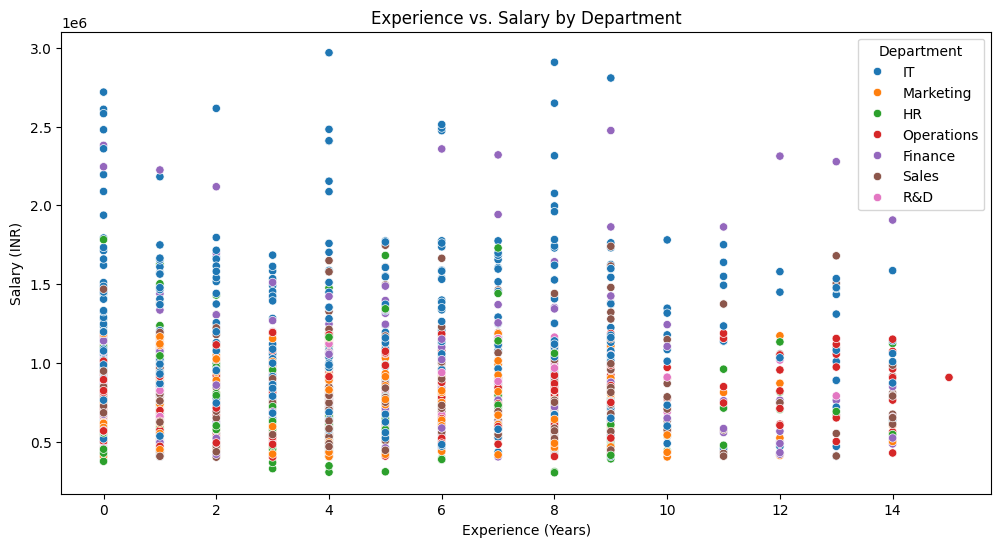

In [ ]:
# Scatter plot showing Experience vs. Salary colored by Department

plt.figure(figsize=(12, 6))
sns.scatterplot(x='Experience_Years', y='Salary_INR', hue='Department', data=df)
plt.title('Experience vs. Salary by Department')
plt.xlabel('Experience (Years)')
plt.ylabel('Salary (INR)')
plt.show()

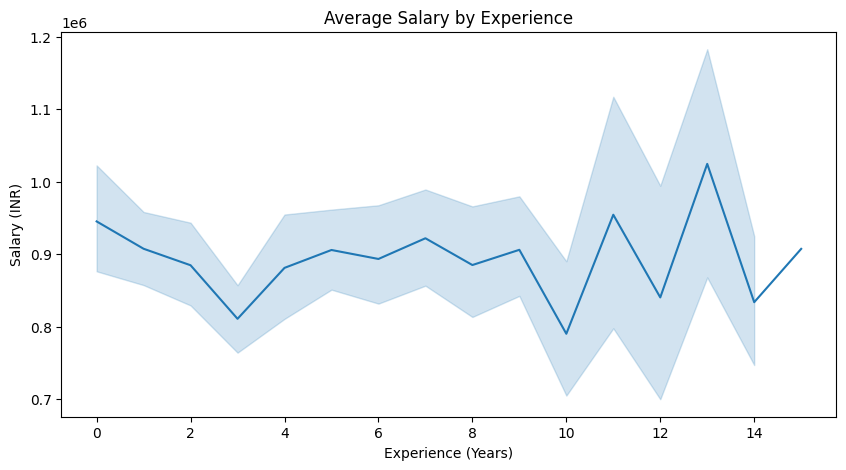

In [ ]:
# Line plot showing average salary trend across Experience_Years

plt.figure(figsize=(10, 5))
sns.lineplot(x='Experience_Years', y='Salary_INR', data=df)
plt.title('Average Salary by Experience')
plt.xlabel('Experience (Years)')
plt.ylabel('Salary (INR)')
plt.show()

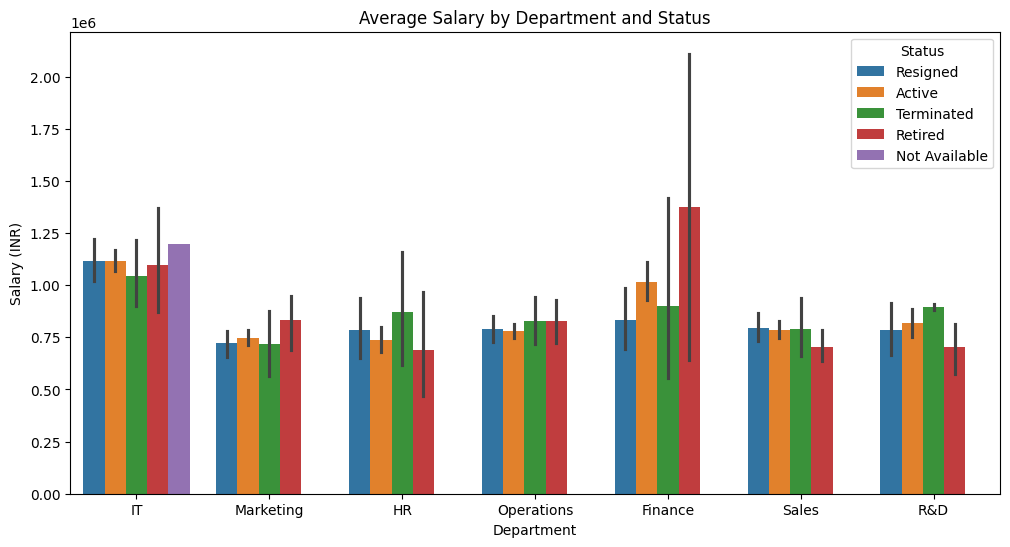

In [ ]:
# Bar plot comparing average salary across Departments split by employment Status

plt.figure(figsize=(12, 6))
sns.barplot(x='Department', y='Salary_INR', hue='Status', data=df)
plt.title('Average Salary by Department and Status')
plt.xlabel('Department')
plt.ylabel('Salary (INR)')
plt.show()

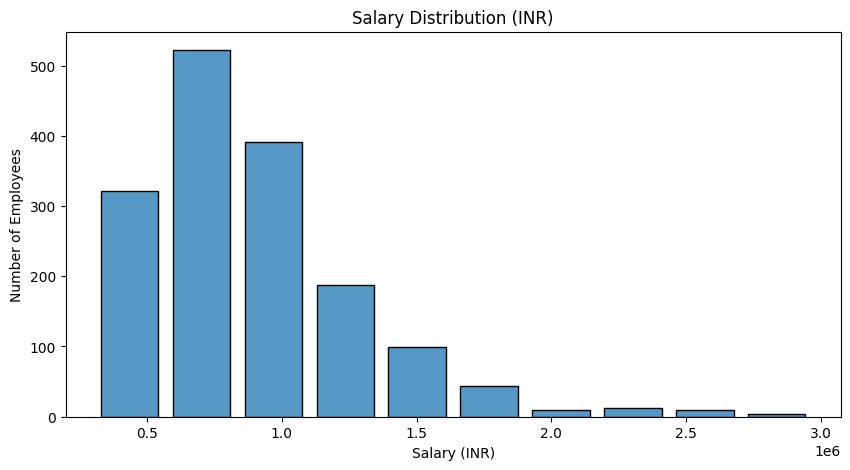

In [ ]:
# Histogram showing the overall distribution of salaries in INR

plt.figure(figsize=(10, 5))
sns.histplot(df['Salary_INR'], bins=10, shrink=0.8)
plt.title('Salary Distribution (INR)')
plt.xlabel('Salary (INR)')
plt.ylabel('Number of Employees')
plt.show()

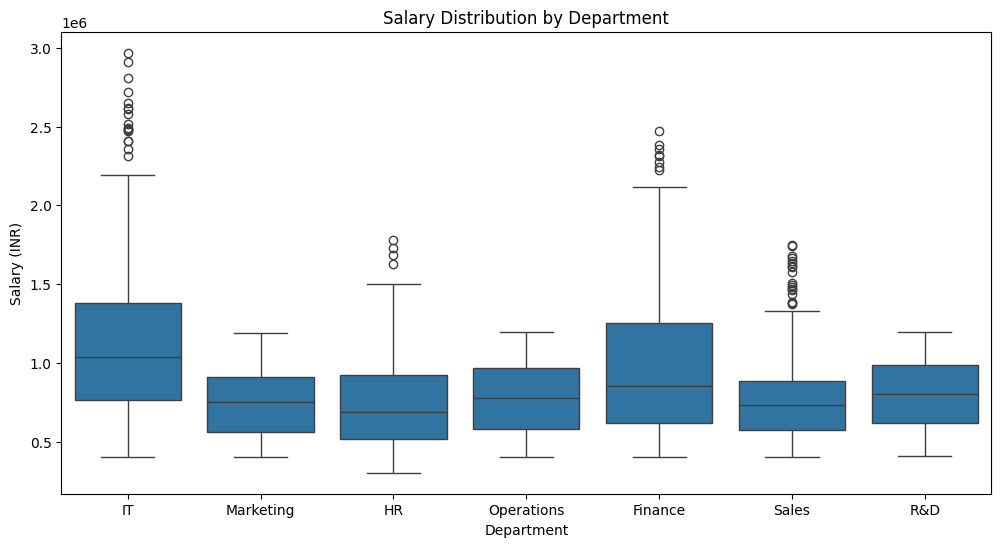

In [ ]:
# Box plot showing salary spread, median, and outliers across Departments

plt.figure(figsize=(12, 6))
sns.boxplot(x='Department', y='Salary_INR', data=df)
plt.title('Salary Distribution by Department')
plt.xlabel('Department')
plt.ylabel('Salary (INR)')
plt.show()

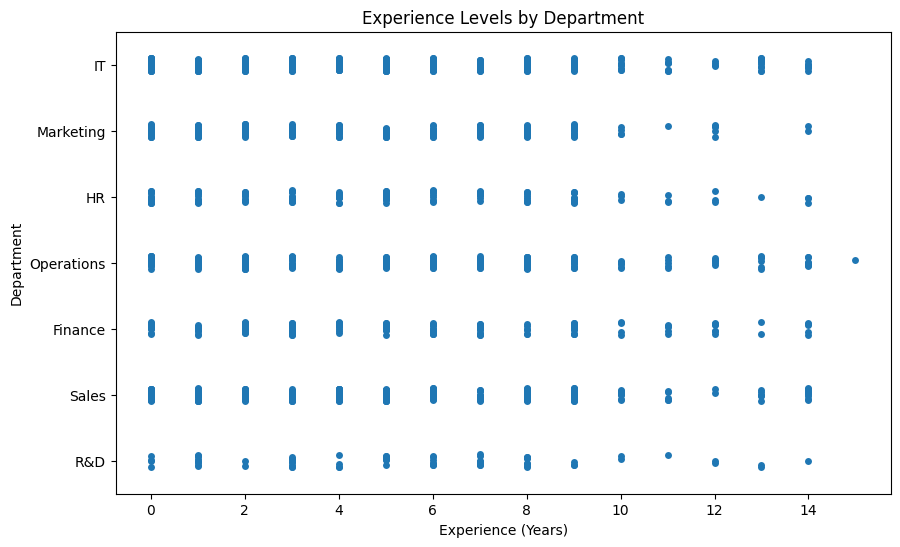

In [ ]:
# Strip plot showing individual experience levels across Departments

plt.figure(figsize=(10, 6))
sns.stripplot(x='Experience_Years', y='Department', data=df)
plt.title('Experience Levels by Department')
plt.xlabel('Experience (Years)')
plt.ylabel('Department')
plt.show()

## 5. Conclusion
In this project, we loaded and explored the HR dataset, cleaned missing values (`Work_Mode`, `Status`, `Experience_Years`, and `Salary_INR`), renamed columns, added a `Bonus` column, and summarized salaries and experience across departments, job titles, and performance ratings.

### Key Takeaways
- **Data Cleaning Matters:** Handling missing values cleanly and converting `Hire_Date` to datetime prevents errors during grouping and plotting.
- **Department & Role Differences:** Grouping and visualizations (`barplot`, `boxplot`, `scatterplot`, `stripplot`) help compare pay ranges, employee counts, and experience levels across departments.
- **Next Steps:** In future projects, I can explore deeper relationships between performance ratings, work modes, and compensation, and refine chart labels and formatting even further.


---

